In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from itertools import combinations

data = pd.read_csv(
    "best_cells_8d_prepared.csv",
    parse_dates=["date"],
)

predictors = ["lai", "sm", "hu", "tg"]

# Assuming each date marks the start of an eight-day window.
data["window_end"] = data["date"] + pd.Timedelta(days=7)

display(data.head())

,lon,lat,date,tg,tn,tx,sm_supplied,hu,lai,sm_days_in_record,sm_valid_days,sm,dTa,year,complete_case,window_end
0,-4.125,41.375,2010-01-01,2.84500,0.52250,5.02125,0.168990,88.100001,0.476,8,5,0.168990,4.49875,2010,True,2010-01-08
1,-4.125,41.375,2010-01-09,2.40750,-1.47500,6.22375,NaN,82.825001,0.472,8,4,NaN,7.69875,2010,False,2010-01-16
2,-4.125,41.375,2010-01-17,7.16500,4.08125,10.32500,0.156495,87.087501,0.492,8,8,0.156495,6.24375,2010,True,2010-01-24
3,-4.125,41.375,2010-01-25,1.84375,-2.36000,6.03625,0.128202,74.462501,0.492,8,6,0.128202,8.39625,2010,True,2010-02-01
4,-4.125,41.375,2010-02-02,5.06625,0.44625,9.55250,0.128452,80.112501,0.488,8,6,0.128452,9.10625,2010,True,2010-02-09


### Define Training and Test Observation

In [2]:
# Training: the entire window must fall within 2010.
train_mask = (
    (data["date"] >= pd.Timestamp("2010-01-01"))
    & (data["window_end"] < pd.Timestamp("2011-01-01"))
)

# Testing: the entire window must fall within 2011.
test_mask = (
    (data["date"] >= pd.Timestamp("2011-01-01"))
    & (data["window_end"] < pd.Timestamp("2012-01-01"))
)

# Require the target and all four predictors to be available.
train = (
    data.loc[train_mask]
    .dropna(subset=["dTa"] + predictors)
    .sort_values(["lon", "lat", "date"])
    .copy()
)

test = (
    data.loc[test_mask]
    .dropna(subset=["dTa"] + predictors)
    .sort_values(["lon", "lat", "date"])
    .copy()
)

sample_counts = pd.concat(
    [
        train.groupby(["lon", "lat"]).size().rename("training"),
        test.groupby(["lon", "lat"]).size().rename("testing"),
    ],
    axis=1,
)

display(sample_counts)

print("Total training observations:", len(train))
print("Total testing observations:", len(test))

assert train["window_end"].max() < pd.Timestamp("2011-01-01")
assert test["date"].min() >= pd.Timestamp("2011-01-01")

,,training,testing
lon,lat,,
-9.125,52.125,38,41
-4.125,41.375,42,43
2.125,45.875,34,35


Total training observations: 114
Total testing observations: 119


### Fit each predictor Separately

In [3]:
single_records = []

for (lon, lat), cell in train.groupby(["lon", "lat"]):
    for predictor in predictors:
        X = sm.add_constant(cell[[predictor]], has_constant="add")
        y = cell["dTa"]

        model = sm.OLS(y, X).fit()

        single_records.append({
            "lon": lon,
            "lat": lat,
            "predictor": predictor,
            "n": int(model.nobs),
            "intercept": model.params["const"],
            "slope": model.params[predictor],
            "adjusted_r2": model.rsquared_adj,
            "p_value": model.pvalues[predictor],
        })

single_results = (
    pd.DataFrame(single_records)
    .sort_values(
        ["lon", "lat", "adjusted_r2"],
        ascending=[True, True, False],
    )
    .reset_index(drop=True)
)

display(
    single_results.style.format({
        "intercept": "{:.4f}",
        "slope": "{:.4f}",
        "adjusted_r2": "{:.4f}",
        "p_value": "{:.3e}",
    })
)

single_results.to_csv("single_predictor_results.csv", index=False)

,lon,lat,predictor,n,intercept,slope,adjusted_r2,p_value
0,-9.125000,52.125000,tg,38,7.3343,-0.1434,0.1356,1.316e-02
1,-9.125000,52.125000,lai,38,8.0010,-0.7870,0.0830,4.415e-02
2,-9.125000,52.125000,hu,38,13.9880,-0.0952,0.0710,5.825e-02
3,-9.125000,52.125000,sm,38,4.4782,3.7606,-0.0261,8.117e-01
4,-4.125000,41.375000,hu,42,25.4448,-0.2183,0.8903,5.140e-21
5,-4.125000,41.375000,tg,42,6.6953,0.4250,0.7272,4.630e-13
6,-4.125000,41.375000,sm,42,21.0957,-79.4571,0.6902,6.000e-12
7,-4.125000,41.375000,lai,42,9.8038,2.8172,0.0352,1.219e-01
8,2.125000,45.875000,hu,34,36.4966,-0.3282,0.7333,6.450e-11
9,2.125000,45.875000,tg,34,6.2611,0.3515,0.3603,1.045e-04


Each model fits:
\[
\Delta T_a = \text{intercept} + \text{slope}\times X
\]
For example, when \(X\) is humidity, the model estimates temperature range using humidity alone.
- add_constant adds the intercept, allowing the fitted line to cross the vertical axis away from zero.
- OLS finds coefficients that minimise the sum of squared prediction errors.
- Adjusted R² measures training fit while penalising additional predictors.
- The p-value tests whether the slope differs from zero under the regression assumptions. Scientific notation prevents small values appearing as zero.

| Cell (lon, lat) | Best predictor | Adjusted R² | Slope | Ordinary OLS p-value |
|---|---|---:|---:|---:|
| −9.125, 52.125 | Mean temperature | 0.1356 | −0.1434 | 0.0132 |
| −4.125, 41.375 | Humidity | 0.8903 | −0.2183 | 5.14 × 10⁻²¹ |
| 2.125, 45.875 | Humidity | 0.7333 | −0.3282 | 6.45 × 10⁻¹¹ |

For example, the middle cell’s humidity model is:
\[
\widehat{\Delta T_a}=25.4448-0.2183\,HU
\]
At 60% humidity, it predicts approximately 12.35°C. A rise from 60% to 70% corresponds to a predicted decrease of 2.18°C.

Three points matter for the explanation:
- Statistical significance and fit are different. Temperature has p < 0.05 in the left cell, but its adjusted R² is only 0.136: a statistically detectable relationship can still explain little variation.
- A large slope does not mean greater importance. Soil moisture’s slope is expressed per 1 m³/m³. In the middle cell, a more realistic increase of 0.01 m³/m³ corresponds to about 0.79°C lower ΔTa.
- These are associations before controlling for seasonality. We cannot yet interpret them as independent physical effects. The ordinary p-values also assume an error structure we still need to examine.

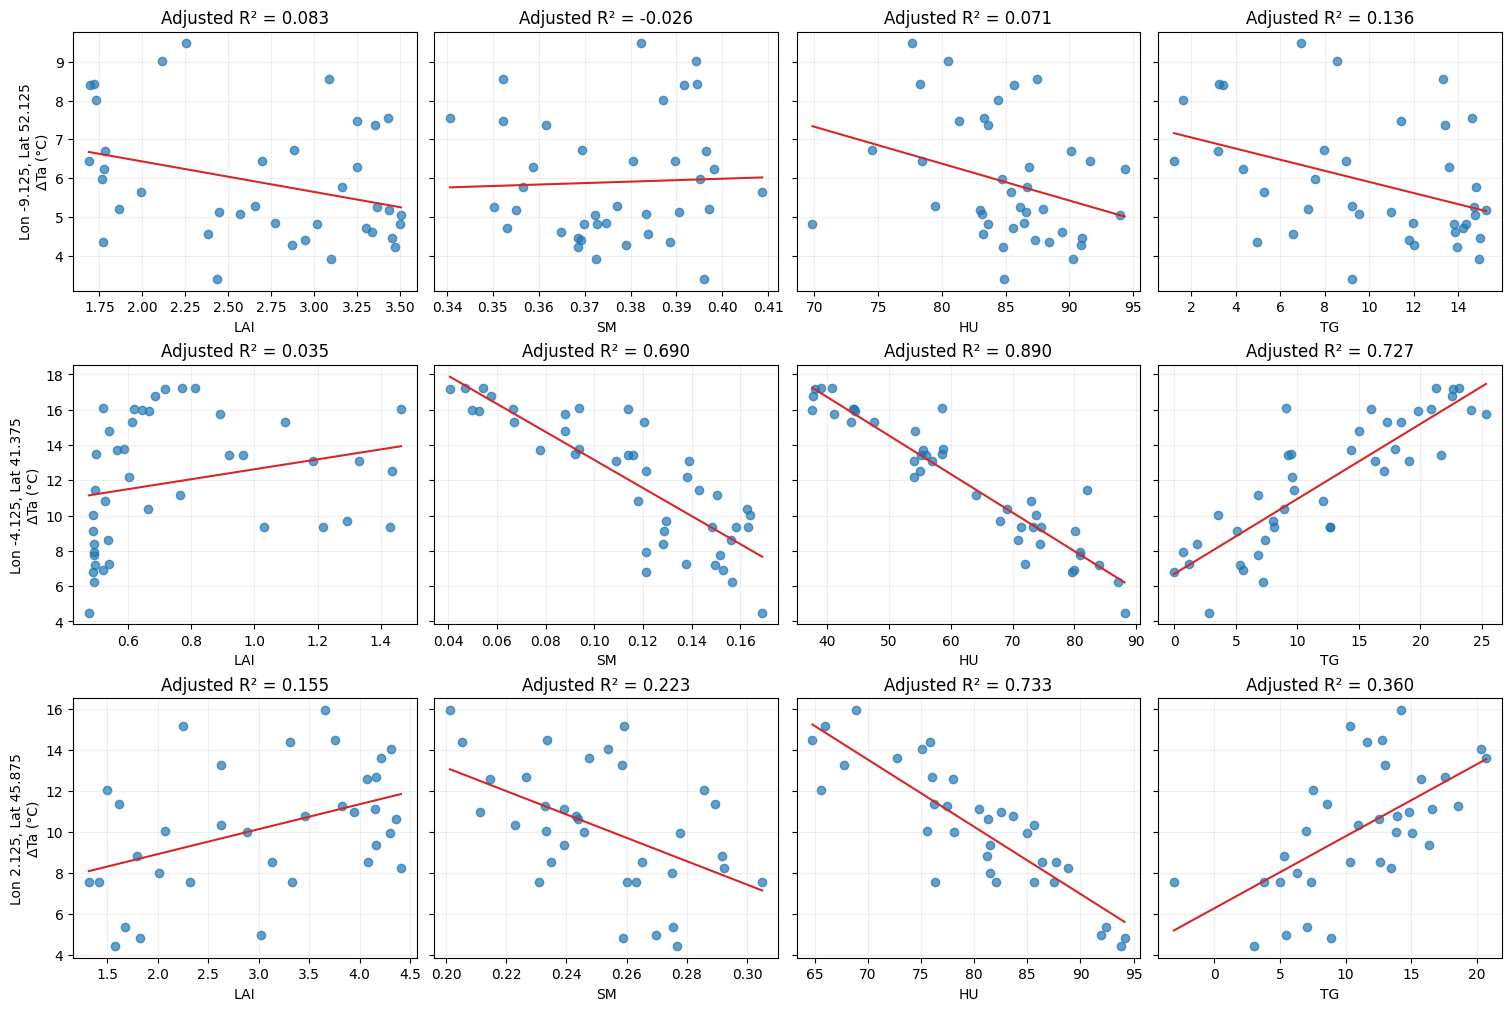

In [4]:
fig, axes = plt.subplots(
    3, 4,
    figsize=(15, 10),
    sharey="row",
    constrained_layout=True,
)

for row, ((lon, lat), cell) in enumerate(
    train.groupby(["lon", "lat"])
):
    for col, predictor in enumerate(predictors):
        ax = axes[row, col]

        result = single_results.loc[
            (single_results["lon"] == lon)
            & (single_results["lat"] == lat)
            & (single_results["predictor"] == predictor)
        ].iloc[0]

        x_line = np.linspace(
            cell[predictor].min(),
            cell[predictor].max(),
            100,
        )

        y_line = result["intercept"] + result["slope"] * x_line

        ax.scatter(cell[predictor], cell["dTa"], alpha=0.7)
        ax.plot(x_line, y_line, color="tab:red")

        ax.set_xlabel(predictor.upper())
        ax.set_title(
            f"Adjusted R² = {result['adjusted_r2']:.3f}"
        )
        ax.grid(alpha=0.2)

        if col == 0:
            ax.set_ylabel(
                f"Lon {lon}, Lat {lat}\nΔTa (°C)"
            )

fig.savefig(
    "04_single_predictor_fits.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


The plots agree with the numerical results. Humidity shows the clearest linear relationship in the middle and bottom rows.

Top row: points are widely scattered around every line. None of the individual predictors explains much variation; the soil moisture line is almost flat.
Middle row: humidity points cluster tightly around a downward line. Soil moisture also has a strong negative association, while temperature has a strong positive association. LAI alone fits poorly.
Bottom row: humidity again provides the strongest fit. The other predictors show more scatter.
A useful distinction: LAI’s positive slope in the middle and bottom cells does not establish that vegetation increases temperature range. LAI may coincide with warmer, sunnier periods. Our seasonal analysis checks how much information it adds beyond the annual cycle.

### Seasonal Features

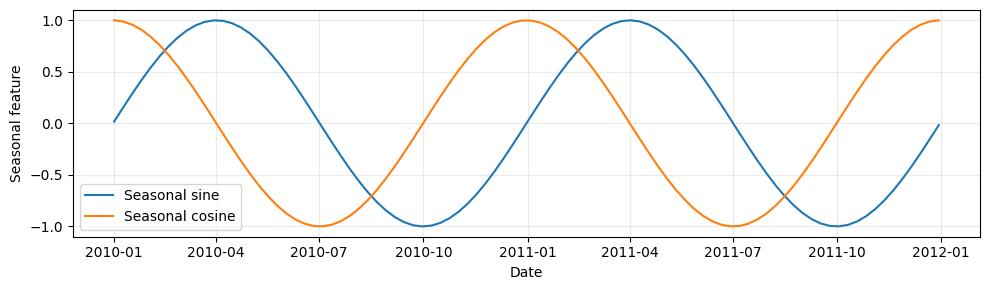

In [5]:
# Follow Jasper's specified day-of-year formulas.
t = data["date"].dt.dayofyear

data["seas_sin"] = np.sin(2 * np.pi * t / 365)
data["seas_cos"] = np.cos(2 * np.pi * t / 365)

# Add the features to the existing, verified training rows.
train["seas_sin"] = data.loc[train.index, "seas_sin"]
train["seas_cos"] = data.loc[train.index, "seas_cos"]

seasonal_dates = (
    data[["date", "seas_sin", "seas_cos"]]
    .drop_duplicates()
    .sort_values("date")
)

fig, ax = plt.subplots(figsize=(10, 3))

ax.plot(
    seasonal_dates["date"],
    seasonal_dates["seas_sin"],
    label="Seasonal sine",
)
ax.plot(
    seasonal_dates["date"],
    seasonal_dates["seas_cos"],
    label="Seasonal cosine",
)

ax.set_xlabel("Date")
ax.set_ylabel("Seasonal feature")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig("02_seasonal_features.png", dpi=300, bbox_inches="tight")
plt.show()

### Compare Seasonal Models

In [6]:
seasonal_specs = {
    "sine_only": ["seas_sin"],
    "cosine_only": ["seas_cos"],
    "seasonal": ["seas_sin", "seas_cos"],
}

for predictor in predictors:
    seasonal_specs[f"seasonal_plus_{predictor}"] = [
        "seas_sin", "seas_cos", predictor
    ]

seasonal_records = []

for (lon, lat), cell in train.groupby(["lon", "lat"]):
    for name, features in seasonal_specs.items():
        X = sm.add_constant(cell[features], has_constant="add")
        model = sm.OLS(cell["dTa"], X).fit()

        # For added-variable models, test the added predictor.
        # For sine/cosine alone, test that individual term.
        tested_feature = None if name == "seasonal" else features[-1]

        seasonal_records.append({
            "lon": lon,
            "lat": lat,
            "model": name,
            "n": int(model.nobs),
            "adjusted_r2": model.rsquared_adj,
            "p_value": (
                model.pvalues[tested_feature]
                if tested_feature is not None
                else np.nan
            ),
        })

seasonal_results = pd.DataFrame(seasonal_records)

baseline = (
    seasonal_results.loc[
        seasonal_results["model"] == "seasonal",
        ["lon", "lat", "adjusted_r2"],
    ]
    .rename(columns={"adjusted_r2": "seasonal_adjusted_r2"})
)

seasonal_results = seasonal_results.merge(
    baseline,
    on=["lon", "lat"],
    validate="many_to_one",
)

is_added = seasonal_results["model"].str.startswith("seasonal_plus_")

seasonal_results["gain_adjusted_r2"] = np.where(
    is_added,
    seasonal_results["adjusted_r2"]
    - seasonal_results["seasonal_adjusted_r2"],
    np.nan,
)

display(
    seasonal_results[
        ["lon", "lat", "model", "n", "adjusted_r2",
         "gain_adjusted_r2", "p_value"]
    ].style.format({
        "adjusted_r2": "{:.4f}",
        "gain_adjusted_r2": "{:.4f}",
        "p_value": "{:.3e}",
    }, na_rep="—")
)

seasonal_results.to_csv("seasonal_model_results.csv", index=False)

,lon,lat,model,n,adjusted_r2,gain_adjusted_r2,p_value
0,-9.125000,52.125000,sine_only,38,0.4019,—,1.156e-05
1,-9.125000,52.125000,cosine_only,38,-0.0214,—,6.374e-01
2,-9.125000,52.125000,seasonal,38,0.3848,—,—
3,-9.125000,52.125000,seasonal_plus_lai,38,0.3676,-0.0172,8.290e-01
4,-9.125000,52.125000,seasonal_plus_sm,38,0.5019,0.1171,4.555e-03
5,-9.125000,52.125000,seasonal_plus_hu,38,0.4319,0.0471,5.637e-02
6,-9.125000,52.125000,seasonal_plus_tg,38,0.4093,0.0245,1.267e-01
7,-4.125000,41.375000,sine_only,42,0.1254,—,1.230e-02
8,-4.125000,41.375000,cosine_only,42,0.5610,—,7.037e-09
9,-4.125000,41.375000,seasonal,42,0.6879,—,—


- Left cell: SM contributes information that its individual model missed. Its relationship becomes useful when the annual cycle is included.
- Middle cell: seasonality already fits much of the variation, but humidity still adds substantial information.
- Right cell: the smooth annual cycle fits relatively little; humidity adds much more explanatory information.
- Adding LAI in the left cell lowers adjusted R². The small improvement in raw fit does not justify the extra coefficient.
The sine-only model outperforming sine + cosine in adjusted R² is also valid: adding a term cannot reduce ordinary training R², but it can reduce adjusted R².

### Select Combinations of physical Predictors

In [7]:
combination_records = []
candidate_models = {}

for (lon, lat), cell in train.groupby(["lon", "lat"]):
    for number in range(1, len(predictors) + 1):
        for combination in combinations(predictors, number):
            features = list(combination)
            name = " + ".join(features)

            X = sm.add_constant(cell[features], has_constant="add")
            model = sm.OLS(cell["dTa"], X).fit()

            candidate_models[(lon, lat, name)] = model

            combination_records.append({
                "lon": lon,
                "lat": lat,
                "model": name,
                "n_predictors": number,
                "n": int(model.nobs),
                "adjusted_r2": model.rsquared_adj,
                "aic": model.aic,
            })

combination_results = pd.DataFrame(combination_records)

combination_results["delta_aic"] = (
    combination_results["aic"]
    - combination_results.groupby(["lon", "lat"])["aic"]
      .transform("min")
)

combination_results["retained"] = (
    (combination_results["delta_aic"] < 2)
    & (combination_results["adjusted_r2"] > 0.36)
)

combination_results = combination_results.sort_values(
    ["lon", "lat", "aic"]
).reset_index(drop=True)

display(
    combination_results.loc[
        combination_results["retained"]
    ].round(4)
)

print("Number retained per cell:")
display(
    combination_results.groupby(["lon", "lat"])["retained"].sum()
)

combination_results.to_csv(
    "all_combination_results.csv", index=False
)

,lon,lat,model,n_predictors,n,adjusted_r2,aic,delta_aic,retained
2,-9.125,52.125,lai + sm + hu + tg,4,38,0.3666,129.3040,0.4044,True
15,-4.125,41.375,sm + hu,2,42,0.8983,133.8671,0.0000,True
16,-4.125,41.375,sm + hu + tg,3,42,0.9003,133.9616,0.0945,True
17,-4.125,41.375,lai + sm + hu + tg,4,42,0.8980,135.7912,1.9241,True
18,-4.125,41.375,lai + hu + tg,3,42,0.8958,135.8135,1.9465,True
19,-4.125,41.375,lai + sm + hu,3,42,0.8956,135.8670,1.9999,True
30,2.125,45.875,sm + hu + tg,3,34,0.9076,95.1648,0.0000,True
31,2.125,45.875,lai + sm + hu + tg,4,34,0.9049,96.9727,1.8079,True


Number retained per cell:


lon     lat   
-9.125  52.125    1
-4.125  41.375    5
 2.125  45.875    2
Name: retained, dtype: int64

### Select and Inspect the final local models

In [8]:
# Select the fewest predictors; use lowest AIC to break ties.
selected = (
    combination_results.loc[combination_results["retained"]]
    .sort_values(["lon", "lat", "n_predictors", "aic", "model"])
    .groupby(["lon", "lat"], sort=False)
    .head(1)
    .copy()
)

# Ensure every cell has a selected model.
assert len(selected) == train.groupby(["lon", "lat"]).ngroups

display(
    selected[
        ["lon", "lat", "model", "n_predictors",
         "n", "adjusted_r2", "delta_aic"]
    ].round(4)
)

# Display the fitted coefficients.
coefficient_records = []

for row in selected.itertuples(index=False):
    model = candidate_models[(row.lon, row.lat, row.model)]

    for term, coefficient in model.params.items():
        coefficient_records.append({
            "lon": row.lon,
            "lat": row.lat,
            "model": row.model,
            "term": term,
            "coefficient": coefficient,
        })

coefficients = pd.DataFrame(coefficient_records)
display(coefficients.round(4))

selected.to_csv("selected_cell_models.csv", index=False)
coefficients.to_csv("selected_cell_coefficients.csv", index=False)

,lon,lat,model,n_predictors,n,adjusted_r2,delta_aic
2,-9.125,52.125,lai + sm + hu + tg,4,38,0.3666,0.4044
15,-4.125,41.375,sm + hu,2,42,0.8983,0.0000
30,2.125,45.875,sm + hu + tg,3,34,0.9076,0.0000


,lon,lat,model,term,coefficient
0,-9.125,52.125,lai + sm + hu + tg,const,47.8800
1,-9.125,52.125,lai + sm + hu + tg,lai,-1.4733
2,-9.125,52.125,lai + sm + hu + tg,sm,-78.9921
3,-9.125,52.125,lai + sm + hu + tg,hu,-0.0778
4,-9.125,52.125,lai + sm + hu + tg,tg,-0.1699
5,-4.125,41.375,sm + hu,const,25.3029
6,-4.125,41.375,sm + hu,sm,-16.9924
7,-4.125,41.375,sm + hu,hu,-0.1843
8,2.125,45.875,sm + hu + tg,const,35.2606
9,2.125,45.875,sm + hu + tg,sm,-19.8969


### Evaluating model on 2011

In [9]:
evaluation_records = []
prediction_frames = []

for row in selected.itertuples(index=False):
    key = (row.lon, row.lat)
    model = candidate_models[(*key, row.model)]
    features = row.model.split(" + ")

    cell_test = test.loc[
        (test["lon"] == row.lon) &
        (test["lat"] == row.lat)
    ].copy()

    cell_train = train.loc[
        (train["lon"] == row.lon) &
        (train["lat"] == row.lat)
    ]

    X_test = sm.add_constant(
        cell_test[features], has_constant="add"
    )
    X_test = X_test[model.model.exog_names]

    predicted = model.predict(X_test)
    errors = predicted - cell_test["dTa"]

    # Simple baseline: always predict this cell's 2010 training mean.
    baseline = cell_train["dTa"].mean()
    baseline_rmse = np.sqrt(
        np.mean((baseline - cell_test["dTa"]) ** 2)
    )

    evaluation_records.append({
        "lon": row.lon,
        "lat": row.lat,
        "model": row.model,
        "n_test": len(cell_test),
        "rmse": np.sqrt(np.mean(errors ** 2)),
        "mean_bias": errors.mean(),
        "training_mean_baseline_rmse": baseline_rmse,
    })

    cell_test["predicted"] = predicted
    cell_test["error"] = errors
    cell_test["model"] = row.model

    prediction_frames.append(
        cell_test[
            ["lon", "lat", "date", "dTa",
             "predicted", "error", "model"]
        ]
    )

evaluation = pd.DataFrame(evaluation_records)
cell_predictions = pd.concat(prediction_frames, ignore_index=True)

display(evaluation.style.format({
    "rmse": "{:.4f}",
    "mean_bias": "{:.4f}",
    "training_mean_baseline_rmse": "{:.4f}",
}))

evaluation.to_csv("cell_model_evaluation_2011.csv", index=False)
cell_predictions.to_csv("cell_predictions_2011.csv", index=False)

,lon,lat,model,n_test,rmse,mean_bias,training_mean_baseline_rmse
0,-9.125000,52.125000,lai + sm + hu + tg,41,2.0347,1.3927,2.1889
1,-4.125000,41.375000,sm + hu,43,2.9706,-2.4578,5.3818
2,2.125000,45.875000,sm + hu + tg,35,1.7630,-0.5423,2.8986


### one pooled model with shared coefficients across all three cells

In [10]:
pooled_records = []
pooled_models = {}

for number in range(1, len(predictors) + 1):
    for combination in combinations(predictors, number):
        features = list(combination)
        name = " + ".join(features)

        X = sm.add_constant(
            train[features], has_constant="add"
        )
        model = sm.OLS(train["dTa"], X).fit()

        pooled_models[name] = model

        pooled_records.append({
            "model": name,
            "n_predictors": number,
            "n": int(model.nobs),
            "adjusted_r2": model.rsquared_adj,
            "aic": model.aic,
        })

pooled_results = pd.DataFrame(pooled_records)

pooled_results["delta_aic"] = (
    pooled_results["aic"] - pooled_results["aic"].min()
)

pooled_results["retained"] = (
    (pooled_results["delta_aic"] < 2) &
    (pooled_results["adjusted_r2"] > 0.36)
)

pooled_results = pooled_results.sort_values("aic")

display(pooled_results.style.format({
    "adjusted_r2": "{:.4f}",
    "aic": "{:.4f}",
    "delta_aic": "{:.4f}",
}))

pooled_selected = (
    pooled_results.loc[pooled_results["retained"]]
    .sort_values(["n_predictors", "aic", "model"])
    .iloc[0]
)

pooled_name = pooled_selected["model"]
pooled_model = pooled_models[pooled_name]

print("Selected pooled model:", pooled_name)
print("Training observations:", int(pooled_model.nobs))

pooled_results.to_csv(
    "pooled_model_selection.csv", index=False
)

,model,n_predictors,n,adjusted_r2,aic,delta_aic,retained
14,lai + sm + hu + tg,4,114,0.8180,442.3191,0.0000,True
10,lai + sm + hu,3,114,0.8134,444.1937,1.8745,True
13,sm + hu + tg,3,114,0.7642,470.8981,28.5790,False
5,lai + hu,2,114,0.7551,474.2058,31.8866,False
12,lai + hu + tg,3,114,0.7542,475.5887,33.2695,False
7,sm + hu,2,114,0.7507,476.2613,33.9421,False
9,hu + tg,2,114,0.7355,482.9857,40.6665,False
2,hu,1,114,0.7290,484.7951,42.4759,False
8,sm + tg,2,114,0.6617,511.0693,68.7502,False
11,lai + sm + tg,3,114,0.6599,512.6412,70.3221,False


Selected pooled model: lai + sm + hu
Training observations: 114


The full model has the lowest AIC, but our rule selects the simpler retained model. Removing TG reduces adjusted R² only slightly.

The pooled adjusted R² combines variation between locations and over time. It does not mean the model performs equally well at every location.

In [11]:
pooled_features = pooled_name.split(" + ")

X_test = sm.add_constant(
    test[pooled_features], has_constant="add"
)
X_test = X_test[pooled_model.model.exog_names]

pooled_predictions = test[
    ["lon", "lat", "date", "dTa"]
].copy()

pooled_predictions["pooled_predicted"] = pooled_model.predict(X_test)

comparison_predictions = cell_predictions.merge(
    pooled_predictions,
    on=["lon", "lat", "date", "dTa"],
    how="inner",
    validate="one_to_one",
)

assert len(comparison_predictions) == len(test)

comparison_records = []

for (lon, lat), cell in comparison_predictions.groupby(["lon", "lat"]):
    cell_error = cell["predicted"] - cell["dTa"]
    pooled_error = cell["pooled_predicted"] - cell["dTa"]

    comparison_records.append({
        "lon": lon,
        "lat": lat,
        "n_test": len(cell),
        "cell_model_rmse": np.sqrt(np.mean(cell_error ** 2)),
        "cell_model_bias": cell_error.mean(),
        "pooled_rmse": np.sqrt(np.mean(pooled_error ** 2)),
        "pooled_bias": pooled_error.mean(),
    })

comparison = pd.DataFrame(comparison_records)

display(comparison.style.format({
    "cell_model_rmse": "{:.4f}",
    "cell_model_bias": "{:.4f}",
    "pooled_rmse": "{:.4f}",
    "pooled_bias": "{:.4f}",
}))

pooled_predictions.to_csv("pooled_predictions_2011.csv", index=False)
comparison.to_csv("cell_vs_pooled_2011.csv", index=False)

,lon,lat,n_test,cell_model_rmse,cell_model_bias,pooled_rmse,pooled_bias
0,-9.125000,52.125000,41,2.0347,1.3927,2.4710,2.0698
1,-4.125000,41.375000,43,2.9706,-2.4578,2.7564,-2.1750
2,2.125000,45.875000,35,1.7630,-0.5423,2.4072,-1.8154


Pooling helps the middle cell slightly, but worsens predictions in the other two cells.
| Cell (lon, lat) | Cell-specific RMSE | Pooled RMSE | Better model |
|---|---:|---:|---|
| −9.125, 52.125 | 2.035°C | 2.471°C | Cell-specific |
| −4.125, 41.375 | 2.971°C | 2.756°C | Pooled |
| 2.125, 45.875 | 1.763°C | 2.407°C | Cell-specific |


Bias follows the same pattern: pooling increases overprediction in the left cell, slightly reduces underprediction in the middle, and increases underprediction in the right.

Reasoning: pooling uses more training observations, but assumes the same relationships at all three locations. That assumption can sacrifice local accuracy. These results suggest that shared coefficients do not work equally well everywhere; they do not establish the physical cause of the differences.

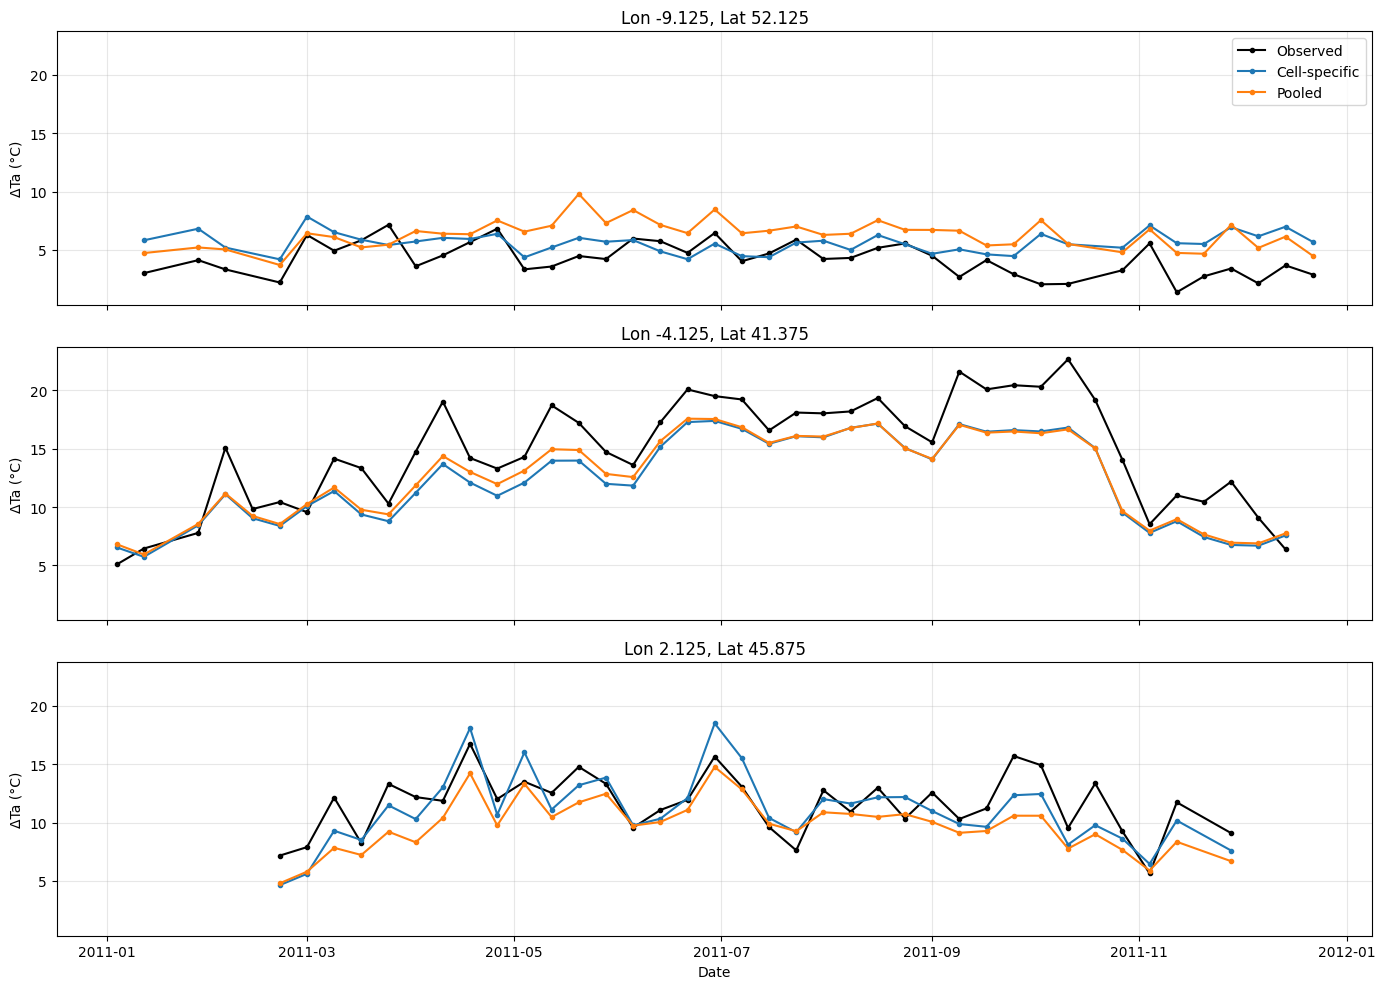

In [12]:
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10), sharex=True, sharey=True
)

for ax, ((lon, lat), cell) in zip(
    axes, comparison_predictions.groupby(["lon", "lat"])
):
    cell = cell.sort_values("date")

    ax.plot(
        cell["date"], cell["dTa"],
        "o-", color="black", markersize=3, label="Observed"
    )
    ax.plot(
        cell["date"], cell["predicted"],
        "o-", markersize=3, label="Cell-specific"
    )
    ax.plot(
        cell["date"], cell["pooled_predicted"],
        "o-", markersize=3, label="Pooled"
    )

    ax.set_title(f"Lon {lon}, Lat {lat}")
    ax.set_ylabel("ΔTa (°C)")
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Date")

fig.tight_layout()
fig.savefig("2011_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

Top cell: both models generally overpredict ΔTa, particularly late in 2011. The pooled model also overpredicts strongly during spring and summer.
Middle cell: both follow the broad seasonal pattern but underestimate many high values, especially around September–October. Their predictions are very similar.
Bottom cell: the cell-specific model follows observations more closely. The pooled model generally predicts lower values and misses several peaks.

In [13]:
range_records = []

for (lon, lat), cell_train in train.groupby(["lon", "lat"]):
    cell_test = test.loc[
        (test["lon"] == lon) &
        (test["lat"] == lat)
    ]

    for variable in predictors + ["dTa"]:
        train_min = cell_train[variable].min()
        train_max = cell_train[variable].max()

        outside = (
            (cell_test[variable] < train_min) |
            (cell_test[variable] > train_max)
        )

        range_records.append({
            "lon": lon,
            "lat": lat,
            "variable": variable,
            "mean_2010": cell_train[variable].mean(),
            "mean_2011": cell_test[variable].mean(),
            "min_2010": train_min,
            "max_2010": train_max,
            "min_2011": cell_test[variable].min(),
            "max_2011": cell_test[variable].max(),
            "test_outside_training_range": int(outside.sum()),
            "n_test": len(cell_test),
        })

range_check = pd.DataFrame(range_records)

display(range_check.style.format({
    column: "{:.3f}"
    for column in [
        "mean_2010", "mean_2011",
        "min_2010", "max_2010",
        "min_2011", "max_2011",
    ]
}))

range_check.to_csv("training_test_range_check.csv", index=False)

,lon,lat,variable,mean_2010,mean_2011,min_2010,max_2010,min_2011,max_2011,test_outside_training_range,n_test
0,-9.125000,52.125000,lai,2.679,2.722,1.688,3.504,1.636,3.572,8,41
1,-9.125000,52.125000,sm,0.376,0.378,0.341,0.409,0.353,0.404,0,41
2,-9.125000,52.125000,hu,85.014,85.234,69.838,94.325,70.963,93.638,0,41
3,-9.125000,52.125000,tg,10.049,10.311,1.225,15.256,3.766,14.551,0,41
4,-9.125000,52.125000,dTa,5.893,4.227,3.387,9.472,1.375,7.152,13,41
5,-4.125000,41.375000,lai,0.751,0.743,0.476,1.464,0.468,1.456,2,43
6,-4.125000,41.375000,sm,0.115,0.100,0.041,0.169,0.039,0.172,3,43
7,-4.125000,41.375000,hu,61.950,61.068,37.600,88.100,37.850,92.500,3,43
8,-4.125000,41.375000,tg,12.294,12.975,-0.034,25.327,0.704,24.295,0,43
9,-4.125000,41.375000,dTa,11.920,14.802,4.499,17.251,5.082,22.656,16,43


| Cell | Change in mean ΔTa, 2010 → 2011 | Interpretation |
|---|---|---|
| −9.125, 52.125 | 5.893 → 4.227°C | The observed range decreased while predictor means stayed similar. The models did not capture the full decrease, producing overprediction. |
| −4.125, 41.375 | 11.920 → 14.802°C | The observed range increased substantially. Both models missed much of this increase, producing underprediction. |
| 2.125, 45.875 | 10.164 → 11.561°C | The observed range increased, and humidity reached values below the training minimum. The local model therefore encountered some extrapolation. |


Two details matter:
- Middle cell: the 2011 maximum ΔTa was 22.656°C, compared with 17.251°C in training. Linear regression can predict beyond its training target range, but these higher outcomes were poorly captured.
- Bottom cell: minimum humidity fell from 64.788% to 51.700%. This is outside that cell’s training range, where the fitted relationship is less well supported.
Similar predictor means do not imply identical conditions: timing, variability, and combinations of predictors can also change. These statistics cover only our complete-case samples.

## Validations

In [14]:
for (lon, lat), cell in train.groupby(["lon", "lat"]):
    print(f"\nLon {lon}, Lat {lat}")

    correlation = cell[predictors].corr()

    display(
        correlation.style
        .format("{:.2f}")
        .background_gradient(
            cmap="RdBu_r", vmin=-1, vmax=1
        )
    )


Lon -9.125, Lat 52.125


,lai,sm,hu,tg
lai,1.00,-0.86,-0.03,0.94
sm,-0.86,1.00,0.08,-0.78
hu,-0.03,0.08,1.00,0.02
tg,0.94,-0.78,0.02,1.00



Lon -4.125, Lat 41.375


,lai,sm,hu,tg
lai,1.00,0.04,-0.31,0.36
sm,0.04,1.00,0.82,-0.73
hu,-0.31,0.82,1.00,-0.87
tg,0.36,-0.73,-0.87,1.00



Lon 2.125, Lat 45.875


,lai,sm,hu,tg
lai,1.00,-0.47,-0.08,0.83
sm,-0.47,1.00,0.24,-0.45
hu,-0.08,0.24,1.00,-0.28
tg,0.83,-0.45,-0.28,1.00


| Cell | Strong correlations | Implication for selected model |
|---|---|---|
| −9.125, 52.125 | LAI–TG **+0.94**; LAI–SM **−0.86** | All are included, making their separate effects difficult to distinguish. |
| −4.125, 41.375 | SM–HU **+0.82**; HU–TG **−0.87** | The selected model includes SM and HU, so their coefficients share overlapping information. |
| 2.125, 45.875 | LAI–TG **+0.83** | LAI was excluded from the selected model, so this pair does not directly affect its coefficient estimates. |



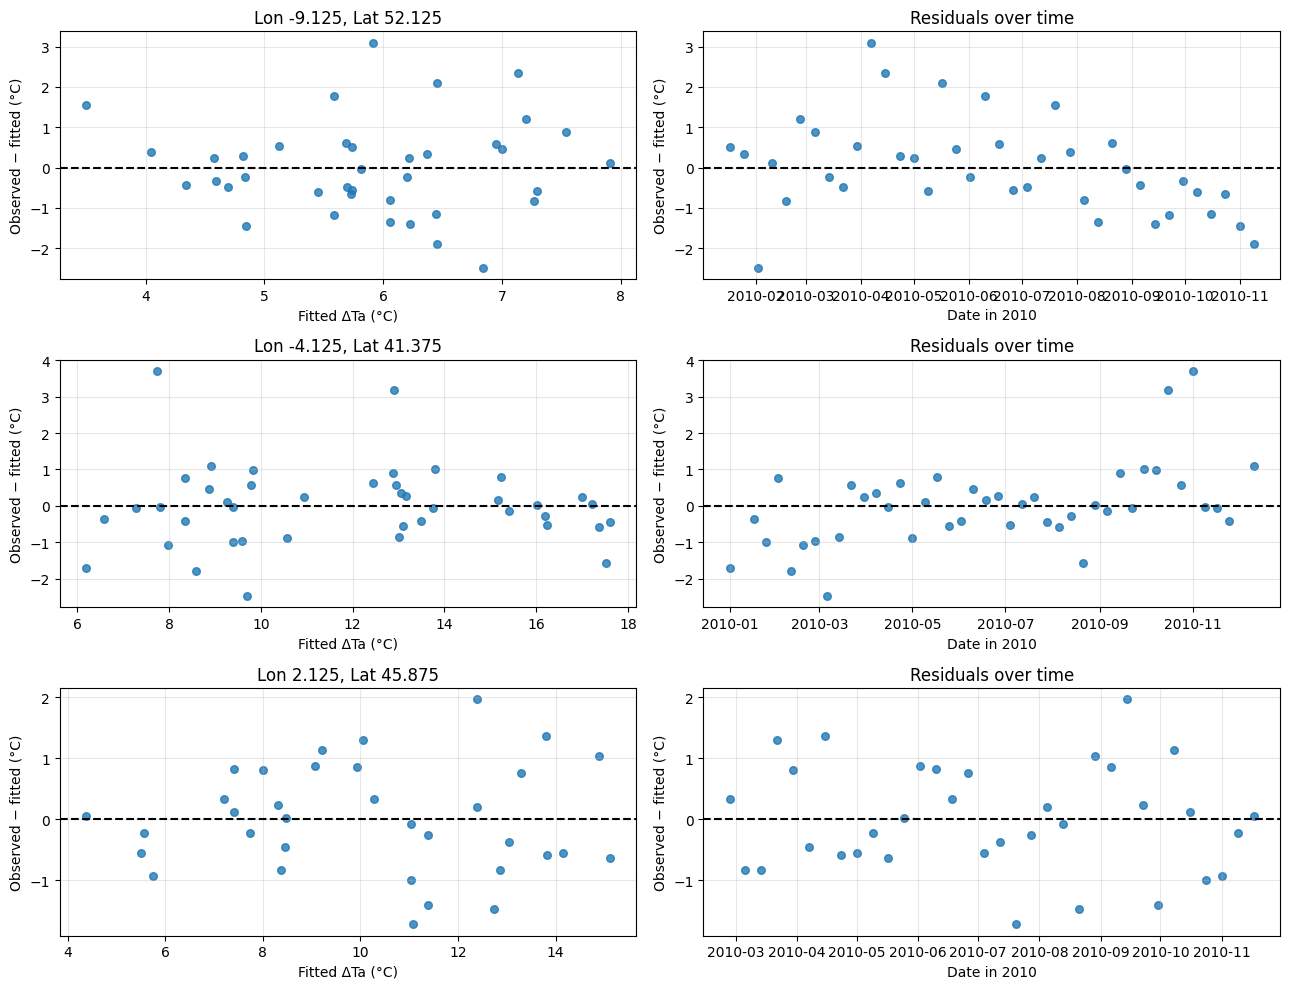

In [15]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))

for i, row in enumerate(selected.itertuples(index=False)):
    model = candidate_models[(row.lon, row.lat, row.model)]

    # Match the exact rows and order used to fit the model.
    cell = train.loc[model.model.data.row_labels]
    fitted = np.asarray(model.fittedvalues)
    residuals = np.asarray(model.resid)

    axes[i, 0].scatter(fitted, residuals, s=30, alpha=0.8)
    axes[i, 0].axhline(0, color="black", linestyle="--")
    axes[i, 0].set_xlabel("Fitted ΔTa (°C)")
    axes[i, 0].set_ylabel("Observed − fitted (°C)")
    axes[i, 0].set_title(
        f"Lon {row.lon}, Lat {row.lat}"
    )

    axes[i, 1].scatter(
        cell["date"], residuals, s=30, alpha=0.8
    )
    axes[i, 1].axhline(0, color="black", linestyle="--")
    axes[i, 1].set_xlabel("Date in 2010")
    axes[i, 1].set_ylabel("Observed − fitted (°C)")
    axes[i, 1].set_title("Residuals over time")

    for ax in axes[i]:
        ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

The residuals show some remaining patterns over time, especially in the top and middle cells.

| Cell | What we see |
|---|---|
| Top | Residuals are mostly negative late in 2010: the model repeatedly overpredicts during that period. |
| Middle | Several negative residuals early in the year and positive ones around September–October suggest missed temporal structure. Two large positive residuals stand out. |
| Bottom | Residuals are more mixed, although some clusters remain. No clear funnel shape is obvious. |

The left-hand plots show no unmistakable curved pattern, but the samples are small. We cannot conclude that the errors are independent or have constant variance from these plots alone.

Also, training residuals averaging approximately zero is expected for OLS with an intercept—it does not guarantee zero bias in 2011.

In [16]:
residual_correlation_records = []

for row in selected.itertuples(index=False):
    model = candidate_models[(row.lon, row.lat, row.model)]
    cell = train.loc[model.model.data.row_labels]

    residual_series = pd.Series(
        np.asarray(model.resid),
        index=pd.DatetimeIndex(cell["date"]),
    ).sort_index()

    # Move each residual forward 8 days to match it
    # with the residual from the following window.
    previous = residual_series.copy()
    previous.index = previous.index + pd.Timedelta(days=8)

    pairs = pd.concat(
        [
            residual_series.rename("current"),
            previous.rename("previous_8d"),
        ],
        axis=1,
    ).dropna()

    residual_correlation_records.append({
        "lon": row.lon,
        "lat": row.lat,
        "n_pairs": len(pairs),
        "residual_correlation_8d": (
            pairs["current"].corr(pairs["previous_8d"])
        ),
    })

residual_correlation = pd.DataFrame(
    residual_correlation_records
)

display(residual_correlation.round(3))

,lon,lat,n_pairs,residual_correlation_8d
0,-9.125,52.125,37,0.350
1,-4.125,41.375,39,0.270
2,2.125,45.875,33,0.082


| Cell (lon, lat) | Eight-day residual correlation | Interpretation |
|---|---:|---|
| −9.125, 52.125 | 0.350 | Some positive persistence |
| −4.125, 41.375 | 0.270 | Weaker positive persistence |
| 2.125, 45.875 | 0.082 | Little correlation at this lag |

For the first cell, an underprediction is somewhat more likely to be followed by another underprediction eight days later; similarly for overprediction.

What this means for our conclusions:
- The reported predictions, RMSE and bias remain unchanged.
- Ordinary OLS p-values assume independent errors. These results flag that assumption for closer examination, especially in the first two cells.
- A small correlation at one lag does not establish independence at all other lags.
- With only 33–39 pairs, these are descriptive estimates, not proof of statistically significant autocorrelation.

Residual diagnostics suggested remaining temporal dependence in two cells, so conventional OLS p-values were interpreted cautiously.